# Interpretação dos modelos

## Objetivo
Examinar os coeficientes da Logistic Regression e a importância de variáveis da Random Forest já treinadas. Este notebook lê somente os pipelines salvos; não carrega o conjunto de teste, não ajusta modelos e não escolhe limiares.

## Como interpretar com cuidado
- Na regressão logística binária, o sinal do coeficiente indica a direção em que o atributo codificado desloca a pontuação do modelo para `yes` ou `no`, mantendo os demais atributos constantes.
- Variáveis numéricas foram padronizadas; seus coeficientes correspondem a uma mudança de um desvio padrão.
- Categorias foram convertidas em indicadores One-Hot. Os coeficientes são pesos dos indicadores codificados e não efeitos causais.
- Na Random Forest, `feature_importances_` soma a redução de impureza atribuída aos atributos nas árvores. Importância não é causalidade e pode favorecer variáveis contínuas ou categóricas com muitos níveis.

O objetivo é entender associações usadas pelos modelos e gerar hipóteses para investigação; não afirmar por que um cliente decidiu aderir.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "results" / "models").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
MODELS_PATH = PROJECT_ROOT / "results" / "models"
FIGURES_PATH = PROJECT_ROOT / "results" / "figures"
TABLES_PATH = PROJECT_ROOT / "results" / "tables"
FIGURES_PATH.mkdir(parents=True, exist_ok=True)
TABLES_PATH.mkdir(parents=True, exist_ok=True)

models = {
    "logistic_regression": joblib.load(MODELS_PATH / "logistic_regression_pipeline.joblib"),
    "random_forest": joblib.load(MODELS_PATH / "random_forest_pipeline.joblib"),
}
print(f"Raiz do projeto: {PROJECT_ROOT}")
print("Pipelines carregados; nenhum dado de teste foi usado nesta análise.")

Raiz do projeto: C:\Users\User\Documents\Codex\2026-11-09\files-pasted-by-the-user-projeto
Pipelines carregados; nenhum dado de teste foi usado nesta análise.


## Preparar nomes dos atributos transformados

Os pipelines guardam o pré-processador ajustado. `get_feature_names_out()` recupera os mesmos nomes e ordem usados pelos classificadores, incluindo as categorias criadas pelo One-Hot Encoding. Mapeamos cada atributo codificado de volta à coluna original para tornar as tabelas mais legíveis.

In [2]:
def get_source_variable(feature_name, original_columns):
    name = feature_name.split("__", maxsplit=1)[-1]
    matches = [
        column for column in original_columns
        if name == column or name.startswith(f"{column}_")
    ]
    return max(matches, key=len) if matches else name

log_pipeline = models["logistic_regression"]
log_classifier = log_pipeline.named_steps["classifier"]
log_preprocessor = log_pipeline.named_steps["preprocessor"]
log_feature_names = log_preprocessor.get_feature_names_out()
original_columns = list(log_preprocessor.feature_names_in_)

if list(log_classifier.classes_) != ["no", "yes"]:
    raise ValueError(f"Ordem inesperada das classes: {log_classifier.classes_}")

log_coefficients = pd.DataFrame({
    "encoded_feature": log_feature_names,
    "source_variable": [get_source_variable(name, original_columns) for name in log_feature_names],
    "coefficient_for_yes": log_classifier.coef_.ravel(),
})
log_coefficients["absolute_coefficient"] = log_coefficients["coefficient_for_yes"].abs()
log_coefficients = log_coefficients.sort_values("absolute_coefficient", ascending=False)

print("Dez atributos com coeficiente mais positivo para yes:")
display(log_coefficients.nlargest(10, "coefficient_for_yes")[
    ["source_variable", "encoded_feature", "coefficient_for_yes"]
].round(4))
print("Dez atributos com coeficiente mais negativo para yes:")
display(log_coefficients.nsmallest(10, "coefficient_for_yes")[
    ["source_variable", "encoded_feature", "coefficient_for_yes"]
].round(4))

log_csv_path = TABLES_PATH / "logistic_regression_coefficients.csv"
log_coefficients.to_csv(log_csv_path, index=False, encoding="utf-8")
print(f"Tabela completa salva em {log_csv_path.relative_to(PROJECT_ROOT)}")

Dez atributos com coeficiente mais positivo para yes:


,source_variable,encoded_feature,coefficient_for_yes
50,month,categorical__month_mar,1.2942
5,cons.price.idx,numeric__cons.price.idx,1.1227
46,month,categorical__month_aug,0.4640
47,month,categorical__month_dec,0.4374
8,nr.employed,numeric__nr.employed,0.4101
7,euribor3m,numeric__euribor3m,0.3889
15,job,categorical__job_retired,0.3474
30,education,categorical__education_illiterate,0.2983
43,contact,categorical__contact_cellular,0.2982
9,was_previously_contacted,numeric__was_previously_contacted,0.2584


Dez atributos com coeficiente mais negativo para yes:


,source_variable,encoded_feature,coefficient_for_yes
4,emp.var.rate,numeric__emp.var.rate,-2.2573
49,month,categorical__month_jun,-0.8074
51,month,categorical__month_may,-0.6539
52,month,categorical__month_nov,-0.5818
44,contact,categorical__contact_telephone,-0.3328
60,poutcome,categorical__poutcome_failure,-0.2892
45,month,categorical__month_apr,-0.2378
22,marital,categorical__marital_divorced,-0.1724
17,job,categorical__job_services,-0.1379
56,day_of_week,categorical__day_of_week_mon,-0.1361


Tabela completa salva em results\tables\logistic_regression_coefficients.csv


Coeficientes positivos deslocam a pontuação linear em direção à classe `yes`; coeficientes negativos deslocam em direção a `no`. O tamanho do peso não mede causalidade. Categorias codificadas devem ser lidas como indicadores dentro do modelo, não como comparação causal entre grupos.

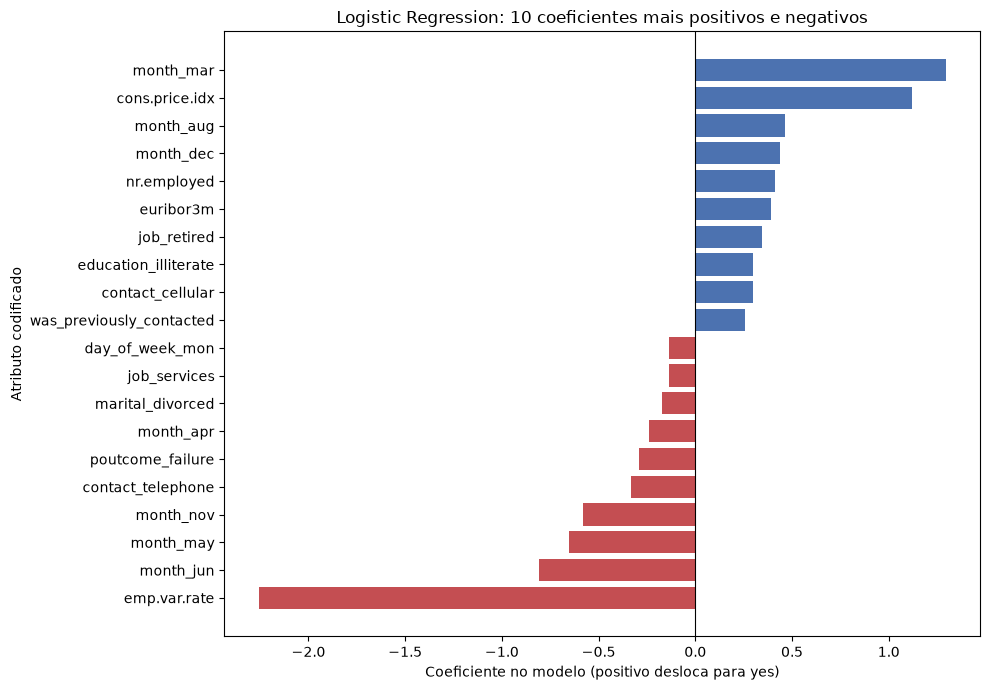

Figura salva em results\figures\logistic_regression_top_coefficients.png


In [3]:
top_positive = log_coefficients.nlargest(10, "coefficient_for_yes")
top_negative = log_coefficients.nsmallest(10, "coefficient_for_yes")
selected_coefficients = pd.concat([top_negative, top_positive]).sort_values("coefficient_for_yes")
colors = ["#C44E52" if value < 0 else "#4C72B0" for value in selected_coefficients["coefficient_for_yes"]]
labels = selected_coefficients["encoded_feature"].str.replace(
    "numeric__", "", regex=False
).str.replace("categorical__", "", regex=False)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(labels, selected_coefficients["coefficient_for_yes"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Logistic Regression: 10 coeficientes mais positivos e negativos",
       xlabel="Coeficiente no modelo (positivo desloca para yes)", ylabel="Atributo codificado")
fig.tight_layout()
log_figure_path = FIGURES_PATH / "logistic_regression_top_coefficients.png"
fig.savefig(log_figure_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Figura salva em {log_figure_path.relative_to(PROJECT_ROOT)}")

## Importância na Random Forest

A importância de impureza indica quanto cada atributo contribuiu para reduzir impureza nos nós das árvores. Como uma coluna categórica vira vários indicadores, somamos os indicadores por coluna original para mostrar um resumo por variável e também inspecionamos os indicadores individuais. Essa soma é útil para leitura, mas pode favorecer colunas com muitos níveis.

In [4]:
rf_pipeline = models["random_forest"]
rf_classifier = rf_pipeline.named_steps["classifier"]
rf_preprocessor = rf_pipeline.named_steps["preprocessor"]
rf_feature_names = rf_preprocessor.get_feature_names_out()
rf_original_columns = list(rf_preprocessor.feature_names_in_)

rf_details = pd.DataFrame({
    "encoded_feature": rf_feature_names,
    "source_variable": [get_source_variable(name, rf_original_columns) for name in rf_feature_names],
    "importance": rf_classifier.feature_importances_,
})
rf_grouped = (
    rf_details.groupby("source_variable", as_index=False)["importance"]
    .sum()
    .sort_values("importance", ascending=False)
)
print("Importância agrupada por variável original:")
display(rf_grouped.head(15).round(4))
print("Quinze atributos codificados mais importantes:")
display(rf_details.nlargest(15, "importance").round(4))

rf_csv_path = TABLES_PATH / "random_forest_feature_importance.csv"
rf_grouped.to_csv(rf_csv_path, index=False, encoding="utf-8")
print(f"Tabela agrupada salva em {rf_csv_path.relative_to(PROJECT_ROOT)}")

Importância agrupada por variável original:


,source_variable,importance
0,age,0.1410
9,euribor3m,0.1237
11,job,0.0989
1,campaign,0.0799
7,education,0.0790
15,nr.employed,0.0708
5,day_of_week,0.0702
13,marital,0.0433
10,housing,0.0398
8,emp.var.rate,0.0334


Quinze atributos codificados mais importantes:


,encoded_feature,source_variable,importance
0,numeric__age,age,0.1410
7,numeric__euribor3m,euribor3m,0.1237
1,numeric__campaign,campaign,0.0799
8,numeric__nr.employed,nr.employed,0.0708
4,numeric__emp.var.rate,emp.var.rate,0.0334
6,numeric__cons.conf.idx,cons.conf.idx,0.0276
5,numeric__cons.price.idx,cons.price.idx,0.0266
39,categorical__housing_yes,housing,0.0188
37,categorical__housing_no,housing,0.0186
9,numeric__was_previously_contacted,was_previously_contacted,0.0176


Tabela agrupada salva em results\tables\random_forest_feature_importance.csv


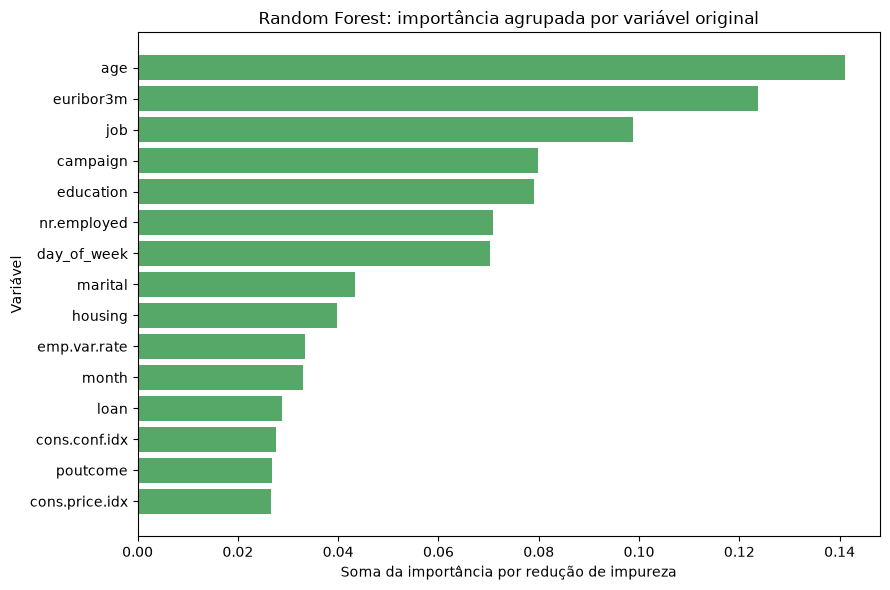

Figura salva em results\figures\random_forest_grouped_importance.png


In [5]:
top_rf = rf_grouped.head(15).sort_values("importance", ascending=True)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_rf["source_variable"], top_rf["importance"], color="#55A868")
ax.set(title="Random Forest: importância agrupada por variável original",
       xlabel="Soma da importância por redução de impureza", ylabel="Variável")
fig.tight_layout()
rf_figure_path = FIGURES_PATH / "random_forest_grouped_importance.png"
fig.savefig(rf_figure_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Figura salva em {rf_figure_path.relative_to(PROJECT_ROOT)}")

## Síntese e implicações

As tabelas e gráficos mostram quais atributos os modelos usaram mais e em que direção a regressão logística associa cada indicador à pontuação de `yes`. São associações aprendidas a partir deste dataset histórico. Não demonstram que uma variável cause a adesão nem que os mesmos padrões se mantenham em outra instituição ou período.

Como hipótese educacional, os padrões podem orientar perguntas para uma campanha futura (por exemplo, quais informações ou períodos merecem ser estudados). Antes de qualquer uso operacional, seria necessária validação prospectiva, análise de estabilidade e avaliação de vieses. O projeto não é um sistema de decisão bancária.